# Assignment 2.2: Advanced Search Problems

**Francisco Gutierrez — AAI-501, Module 2**

## Problem definition

The objective is to find the shortest driving distance from Oracle Park to the Palace of Fine Arts in San Francisco. OSMnx loads the driving network from OpenStreetMap, and NetworkX searches that network using Dijkstra’s algorithm and A*.

The states are street-network nodes, and actions follow outgoing road segments. The starting and goal states are the nodes nearest the two landmarks. Each edge has a length in meters, and the objective is to minimize the sum of these lengths. The driving network preserves road direction, including one-way streets. The objective is distance rather than travel time.

## Libraries

This notebook requires `networkx`, `osmnx`, and `matplotlib`. Install them in the notebook environment before running the cells.


In [2]:
import networkx as nx
import matplotlib.pyplot as plt

## San Francisco driving network


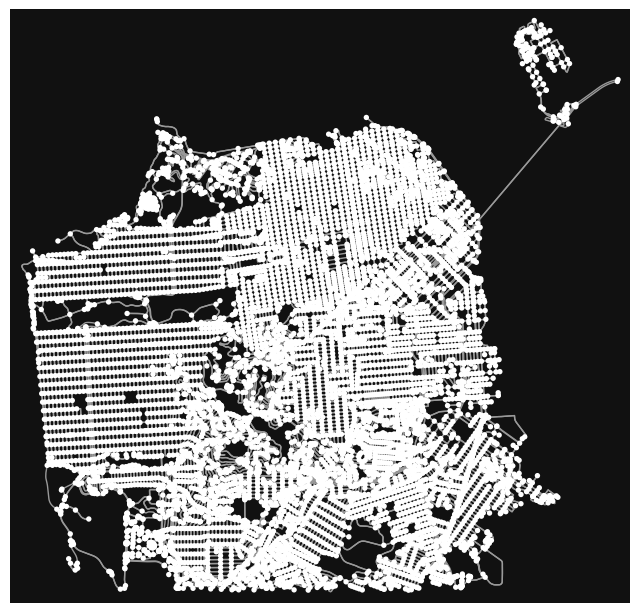

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [10]:
import osmnx as ox
G = ox.graph_from_place('San Francisco, California, USA', network_type='drive')
ox.plot_graph(G)

## Landmark coordinates


In [11]:
oracle_coords = ox.geocode('Oracle Park, San Francisco, California, USA')
print(oracle_coords)

(37.7786059, -122.3894716)


In [12]:
palace_coords = ox.geocode('Palace of Fine Arts, San Francisco, California, USA')
print(palace_coords)

(37.8029186, -122.4484029)


## Starting and goal nodes

Snap each landmark to its nearest node in the driving network. These nodes approximate the endpoints; they may differ from the actual vehicle entrances.


In [13]:
oracle_node = ox.nearest_nodes(G, oracle_coords[1], oracle_coords[0])
palace_node = ox.nearest_nodes(G, palace_coords[1], palace_coords[0])
print("Oracle Park node:", oracle_node)
print("Palace of Fine Arts node:", palace_node)

Oracle Park node: 257316381
Palace of Fine Arts node: 2080819762


## Dijkstra’s shortest route


In [16]:
dijkstra_route = nx.dijkstra_path(G, source=oracle_node, target=palace_node, weight='length')
print("Dijkstra's shortest path from Oracle Park to Palace of Fine Arts:", dijkstra_route)
print("Length of the path (meters):", nx.dijkstra_path_length(G, source=oracle_node, target=palace_node, weight='length'))

Dijkstra's shortest path from Oracle Park to Palace of Fine Arts: [257316381, 257316060, 6311883028, 65315452, 65290178, 258965489, 65290184, 65317709, 890045127, 5950549665, 65306787, 65329405, 258756405, 1723768799, 65307349, 317122247, 65307352, 65307354, 65307356, 65307359, 65356180, 65336947, 65359314, 65305832, 4188186120, 65337383, 65374820, 65372833, 612767658, 330661310, 612767847, 330660359, 330662141, 4019577207, 5610843322, 330666993, 330667561, 330668008, 330669717, 65326702, 65364443, 11337040863, 330657229, 330657200, 65296818, 7231176087, 65296822, 65296824, 65296827, 65296833, 260336116, 65296837, 65296839, 65296846, 65296848, 542900782, 65296849, 65292804, 65296850, 4009044899, 65296852, 258956662, 2980617845, 65345881, 65341696, 65357250, 65353027, 65303205, 65303209, 65301601, 4008987881, 12952646366, 262258030, 65307639, 3685177529, 2080819762]
Length of the path (meters): 7577.2248354203975


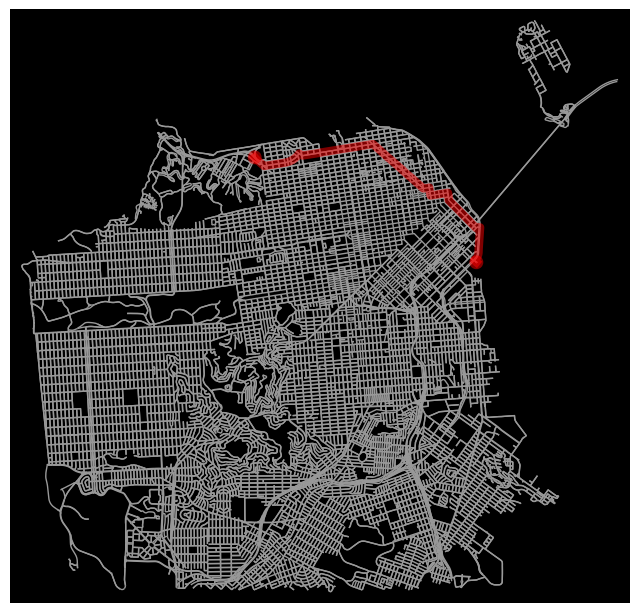

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [20]:
ox.plot_graph_route(G, dijkstra_route, route_linewidth=6, node_size=0, bgcolor='k', route_color='r', orig_dest_size=100)

## A* heuristic

Estimate the remaining distance using great-circle distance in meters, matching the road-length units.


In [23]:
def distance_heuristic(current_node, target_node):
    current = G.nodes[current_node]
    target = G.nodes[target_node]
    # Calculate great-circle distance between the two nodes in meters
    return ox.distance.great_circle(current['y'], current['x'], target['y'], target['x'])


## A* shortest route


In [24]:
astar_route = nx.astar_path(G, source=oracle_node, target=palace_node, heuristic=distance_heuristic, weight='length')
print("A* shortest path from Oracle Park to Palace of Fine Arts:", astar_route)
print("Length of the path (meters):", nx.astar_path_length(G, source=oracle_node, target=palace_node, heuristic=distance_heuristic, weight='length'))

A* shortest path from Oracle Park to Palace of Fine Arts: [257316381, 257316060, 6311883028, 65315452, 65290178, 258965489, 65290184, 65317709, 890045127, 5950549665, 65306787, 65329405, 258756405, 1723768799, 65307349, 317122247, 65307352, 65307354, 65307356, 65307359, 65356180, 65336947, 65359314, 65305832, 4188186120, 65337383, 65374820, 65372833, 612767658, 330661310, 612767847, 330660359, 330662141, 4019577207, 5610843322, 330666993, 330667561, 330668008, 330669717, 65326702, 65364443, 11337040863, 330657229, 330657200, 65296818, 7231176087, 65296822, 65296824, 65296827, 65296833, 260336116, 65296837, 65296839, 65296846, 65296848, 542900782, 65296849, 65292804, 65296850, 4009044899, 65296852, 258956662, 2980617845, 65345881, 65341696, 65357250, 65353027, 65303205, 65303209, 65301601, 4008987881, 12952646366, 262258030, 65307639, 3685177529, 2080819762]
Length of the path (meters): 7577.2248354203975


## Compare results


In [27]:
dijkstra_distance = nx.dijkstra_path_length(G, source=oracle_node, target=palace_node, weight='length')
astar_distance = nx.astar_path_length(G, source=oracle_node, target=palace_node, heuristic=distance_heuristic, weight='length')
print(f"Dijkstra's distance: {dijkstra_distance:.2f}")
print(f"A* distance: {astar_distance:.2f}")

Dijkstra's distance: 7577.22
A* distance: 7577.22


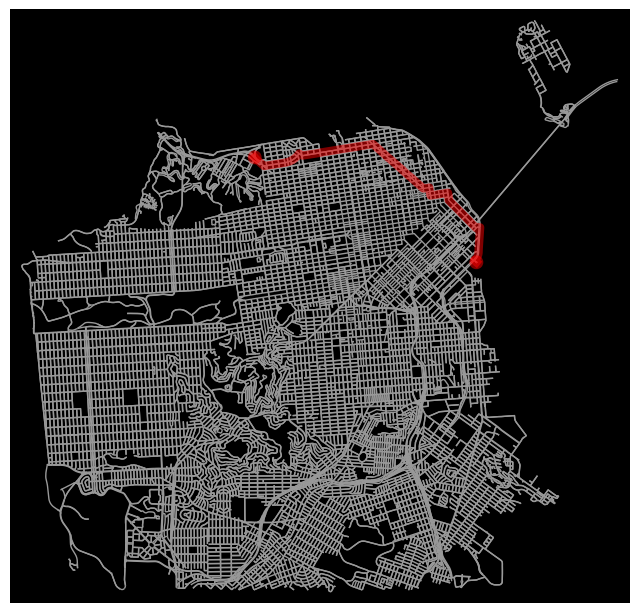

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [29]:
ox.plot_graph_route(G, astar_route, route_linewidth=6, node_size=0, bgcolor='k', route_color='r', orig_dest_size=100)

In [30]:
print("Same route: ", dijkstra_route == astar_route)

Same route:  True


### Algorithm choices

I chose Dijkstra’s algorithm and A* primarily because they were used in the lecture examples. I am still learning about other search algorithms, and this assignment gave me an opportunity to apply these two methods to a real road network.

**Dijkstra’s algorithm** was a good choice because road lengths are nonnegative, and it finds the route with the lowest total distance. It also provided a baseline for checking the result from A*.

**A*** was a good choice because it uses a heuristic to guide its search toward the destination. I used great-circle distance in meters to estimate the remaining distance, matching the units of the road lengths. This direct geographic distance provides a lower bound on the driving distance, allowing A* to find an optimal route while potentially exploring fewer nodes than Dijkstra’s algorithm. I did not measure runtime or the number of nodes explored, so I cannot conclude that A* was faster in this experiment.

### Results

Both algorithms returned the same sequence of nodes, with a total driving distance of approximately **7,577.22 meters (7.58 kilometers or 4.71 miles)** between the selected street-network nodes near Oracle Park and the Palace of Fine Arts. Their agreement supports the result and shows that both methods found the same minimum-distance route in this network.


## Reflection and potential improvements

One improvement I would like to explore is finding the fastest route instead of only the shortest route. My current solution uses road lengths, so it does not account for traffic, speed limits, or delays at intersections. A shorter route could take longer to drive, especially during rush hour or around an event at Oracle Park. With more time and knowledge, I would like to learn how to use estimated travel times as the edge weights and compare the resulting route with the shortest-distance route. I would also need to adjust the A* heuristic to estimate time instead of distance so that the units match.

Another improvement would be choosing more accurate starting and ending points. In this assignment, I used the street-network nodes nearest the coordinates of each landmark. Those nodes may not represent the best vehicle entrance, parking area, or drop-off location. I would like to check the endpoints more carefully and learn how to account for turn restrictions and temporary road closures. This would help make the route more useful for someone actually driving between the two locations, rather than only finding a path between nearby network nodes.

I would also like to better understand how the algorithms differ in efficiency. Dijkstra’s algorithm and A* returned the same route and distance, but I did not measure their runtime or how many nodes they explored. With more experience, I would compare these measurements across several routes and repeat the timing measurements to reduce the effect of small variations. I would also study whether a more informative heuristic could help A* explore fewer nodes while still finding the shortest route. Since I am still learning these algorithms, understanding why a heuristic must not overestimate the remaining cost would be an important next step.

Finally, I would improve how I validate and reproduce the results. The agreement between Dijkstra’s algorithm and A* is useful, but both algorithms use the same road network and endpoints, so they could share the same data limitations. I would like to compare the route with another mapping source and investigate any differences instead of assuming one result is automatically correct. I would also save the downloaded network and record when it was obtained, especially because I encountered a busy map-data server while working on this assignment. These steps would make it easier to rerun the analysis and explain how changes in the map data or endpoint choices might affect the result.
